In [1]:
# ============================================================
# CELL 1: Environment
# ============================================================
import sys, sklearn, pandas as pd, numpy as np
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.10.11
scikit-learn: 1.7.2
pandas: 2.3.3
numpy: 2.2.6


In [2]:
# ============================================================
# CELL 2: Build multilingual stopwords file (Hindi, Hinglish,
#         Nepali, Tamil, Telugu, English)
# ============================================================
import json
from pathlib import Path

STOPWORDS_PATH = Path("multilingual_stopwords.json")

HINDI_STOPWORDS = {
    "का", "के", "की", "को", "में", "से", "पर", "और", "या", "एक",
    "यह", "वह", "ये", "वे", "है", "हैं", "था", "थी", "थे", "हो",
    "होता", "होती", "होते", "कर", "करना", "किया", "कि", "जो", "तो",
    "भी", "नहीं", "न", "ही", "तक", "लिए", "साथ", "बाद", "पहले",
    "अपना", "अपनी", "अपने", "इस", "उस", "इन", "उन", "कुछ", "सब",
    "कोई", "कैसे", "क्या", "क्यों", "कब", "कहाँ", "जब", "तब", "अब",
    "मैं", "हम", "तुम", "आप", "वो", "मुझे", "हमें", "तुम्हें", "आपको",
    "रहा", "रही", "रहे", "गया", "गई", "गए", "दिया", "दी", "दिए",
    "लिया", "ली", "लिए", "बहुत", "कम", "ज़्यादा", "अधिक", "हर", "सिर्फ",
}

HINGLISH_STOPWORDS = {
    "hai", "hain", "haan", "nahi", "nahin", "na", "ki", "ka", "ke", "ko",
    "ne", "me", "mein", "se", "hi", "jo", "to", "ta", "te", "ti",
    "par", "pe", "ra", "ri", "ro", "naa", "ji", "jee", "ha",
    "kya", "kyun", "kyu", "kaise", "kab", "kahan", "kahin", "kisi", "kuch",
    "aisa", "waise", "ab", "tab", "jab", "abhi", "phir", "fir", "baad",
    "pehle", "saath", "sath", "liye", "hota", "hoti", "hote", "hua", "hui",
    "hue", "gaya", "gayi", "gaye", "jaa", "ja", "raha", "rahi", "rahe",
    "kar", "karke", "karna", "karni", "karne", "diya", "di", "de", "do",
    "le", "li", "lo", "tha", "thi", "the", "hu", "hoon", "hey", "hello",
    "hm", "hmm", "ok", "okay", "bas", "bhi", "bohot", "bahut",
    "acha", "accha", "achha", "bhai", "bro", "yaar", "matlab", "sirf",
    "wala", "wali", "wale", "koi", "koyi", "ek", "do", "teen", "char",
    "paisa", "time", "log", "baat", "cheez", "karo", "karte",
}

TELUGU_EXTRA = {
    "మరియు", "ఈ", "ఆ", "ఒక", "కు", "లో", "తో", "యొక్క", "కోసం",
    "అది", "ఇది", "వారు", "అయిన", "గా", "నుండి", "పై", "కి",
    "చేసిన", "అన్ని", "ఉన్న", "లేదు", "కాదు", "మాత్రమే",
}

def try_load_library_stopwords():
    sw = {}
    try:
        import advertools as adv
        for lang in ["nepali", "tamil", "telugu"]:
            if lang in adv.stopwords:
                sw[lang] = set(adv.stopwords[lang])
        print(f"advertools loaded: {list(sw.keys())}")
    except Exception as e:
        print(f"advertools unavailable ({e}); using fallback lists.")
    try:
        from nltk.corpus import stopwords as nltk_sw
        if "nepali" not in sw:
            sw["nepali"] = set(nltk_sw.words("nepali"))
            print("NLTK loaded nepali")
    except Exception:
        pass
    return sw

lib_sw = try_load_library_stopwords()

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

STOPWORDS_DICT = {
    "hindi":    sorted(HINDI_STOPWORDS),
    "hinglish": sorted(HINGLISH_STOPWORDS),
    "nepali":   sorted(lib_sw.get("nepali", set())),
    "tamil":    sorted(lib_sw.get("tamil", set())),
    "telugu":   sorted(set(lib_sw.get("telugu", set())) | TELUGU_EXTRA),
    "english":  sorted(ENGLISH_STOP_WORDS),
}

with open(STOPWORDS_PATH, "w", encoding="utf-8") as f:
    json.dump(STOPWORDS_DICT, f, ensure_ascii=False, indent=2)

print(f"\nStopwords file saved: {STOPWORDS_PATH}")
for lang, words in STOPWORDS_DICT.items():
    print(f"  {lang:10s}: {len(words)} words")

advertools unavailable (No module named 'advertools'); using fallback lists.
NLTK loaded nepali

Stopwords file saved: multilingual_stopwords.json
  hindi     : 82 words
  hinglish  : 115 words
  nepali    : 254 words
  tamil     : 0 words
  telugu    : 23 words
  english   : 318 words


In [3]:
# ============================================================
# CELL 3: Load stopwords + multilingual tokenizer
# ============================================================
import json, re
from pathlib import Path

with open(Path("multilingual_stopwords.json"), "r", encoding="utf-8") as f:
    STOPWORDS_DICT = json.load(f)

ALL_STOPWORDS = set()
for words in STOPWORDS_DICT.values():
    ALL_STOPWORDS.update(w.lower() for w in words)
print(f"Total unique stopwords: {len(ALL_STOPWORDS)}")

# Unicode ranges: Latin, Devanagari (Hindi/Nepali), Tamil, Telugu
TOKEN_PATTERN = re.compile(r"[A-Za-z\u0900-\u097F\u0B80-\u0BFF\u0C00-\u0C7F]+", re.UNICODE)

def tokenize_and_filter(text):
    if not isinstance(text, str):
        return []
    tokens = TOKEN_PATTERN.findall(text.lower())
    return [
        t for t in tokens
        if t not in ALL_STOPWORDS and not (len(t) == 1 and t.isascii())
    ]

print(tokenize_and_filter("यह एक अच्छा जवाब है, but Hinglish bhi hai"))

Total unique stopwords: 772
['अच्छा', 'जवाब', 'hinglish']


In [4]:
# ============================================================
# CELL 4: Load raw files and merge
# ============================================================
import pandas as pd, numpy as np
from pathlib import Path

BASE_DIR = Path(r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark")
DATA_PATH       = BASE_DIR / "data/annotations/final/final_annotations.csv"
RESPONSES_PATH  = BASE_DIR / "data/annotations/working/responses.json"
REFERENCES_PATH = BASE_DIR / "data/annotations/working/references.json"

responses_df   = pd.read_json(RESPONSES_PATH)
references_df  = pd.read_json(REFERENCES_PATH)
annotations_df = pd.read_csv(DATA_PATH)

# Normalize keys
for df in [responses_df, references_df, annotations_df]:
    if "question_id" in df.columns:
        df["question_id"] = df["question_id"].astype("string").str.strip()
    if "language" in df.columns:
        df["language"] = df["language"].astype("string").str.strip().str.upper()
    if "model_name" in df.columns:
        df["model_name"] = df["model_name"].astype("string").str.strip()

LANGUAGE_ALIASES = {"HIEN": "HI-EN", "HI_EN": "HI-EN", "HINGLISH": "HI-EN"}
for df in [responses_df, annotations_df]:
    df["language"] = df["language"].replace(LANGUAGE_ALIASES)

assert references_df["question_id"].is_unique
KEYS = ["question_id", "language", "model_name"]
assert not responses_df.duplicated(KEYS).any()
assert not annotations_df.duplicated(KEYS).any()

refs_slim = references_df.drop(
    columns=["fact_id", "domain", "difficulty", "source_url"], errors="ignore"
)

merged = responses_df.merge(
    refs_slim, on="question_id", how="left",
    validate="many_to_one", suffixes=("_resp", "_ref"),
)
merged = merged.merge(
    annotations_df[KEYS + ["response_id", "correctness_label",
                           "hallucination_types", "severity",
                           "confidence", "judge_model"]],
    on=KEYS, how="left", validate="one_to_one",
)

print("Merged rows:", len(merged))
print(merged["correctness_label"].value_counts(dropna=False))

C:\Users\CH.SC.U4CSE23160\AppData\Local\Temp\ipykernel_5512\2138303805.py:14: DtypeWarning: Columns (14,19) have mixed types. Specify dtype option on import or set low_memory=False.
  annotations_df = pd.read_csv(DATA_PATH)


Merged rows: 64800
correctness_label
Correct              39459
Incorrect            13092
Partially Correct    12249
Name: count, dtype: int64


In [5]:
# ============================================================
# CELL 5: Clean + label encode + input_text
# ============================================================
from sklearn.preprocessing import LabelEncoder

for col in ["question", "ground_truth", "response"]:
    merged[col] = merged[col].fillna("").astype(str).str.strip()

merged = merged[
    (merged["question"] != "") &
    (merged["ground_truth"] != "") &
    (merged["response"] != "")
].copy()

LABEL_FIX = {
    "correct": "Correct", "incorrect": "Incorrect",
    "partially correct": "Partially Correct",
    "partial": "Partially Correct", "uncertain": "Uncertain",
}
merged["correctness_label"] = (
    merged["correctness_label"].astype("string").str.strip().replace(LABEL_FIX)
)
VALID = {"Correct", "Partially Correct", "Incorrect", "Uncertain"}
bad = set(merged["correctness_label"].dropna()) - VALID
assert not bad, f"Unexpected labels: {bad}"
merged = merged.dropna(subset=["correctness_label"]).copy()

merged["input_text"] = merged.apply(
    lambda r: (
        f"Question: {r['question']}\n"
        f"Ground Truth: {r['ground_truth']}\n"
        f"Model Response: {r['response']}"
    ),
    axis=1,
)

le = LabelEncoder()
merged["label"] = le.fit_transform(merged["correctness_label"])
LABELS = list(le.classes_)
NUM_LABELS = len(LABELS)
print("Labels:", LABELS)
print("Rows after cleaning:", len(merged))

Labels: ['Correct', 'Incorrect', 'Partially Correct']
Rows after cleaning: 64800


In [6]:
# ============================================================
# CELL 6: StratifiedGroupKFold split (identical to transformer runs)
# ============================================================
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np

SEED = 42

# Prefer fact_id, fall back to question_id
def pick_fact_id_col(df):
    for c in ["fact_id", "fact_id_resp", "fact_id_ref",
              "fact_id_response", "fact_id_reference"]:
        if c in df.columns:
            return c
    return None

fact_col = pick_fact_id_col(merged)
if fact_col is None:
    merged["split_group"] = "QUESTION_" + merged["question_id"].astype(str)
else:
    ids = merged[fact_col].astype(str).str.strip()
    invalid = ids.isin(["", "nan", "None", "<NA>"]) | merged[fact_col].isna()
    merged["split_group"] = np.where(
        ~invalid, "FACT_" + ids,
        "QUESTION_" + merged["question_id"].astype(str),
    )

# 15% test
sgkf_test = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = list(sgkf_test.split(merged["input_text"], merged["label"],
                             groups=merged["split_group"]))
test_pos = np.concatenate([folds[i][1] for i in range(3)])
remaining_idx = np.setdiff1d(np.arange(len(merged)), test_pos)

remaining = merged.iloc[remaining_idx].reset_index(drop=True)
test_df   = merged.iloc[test_pos].reset_index(drop=True).copy()

# ~15% dev of remaining
sgkf_dev = StratifiedGroupKFold(n_splits=17, shuffle=True, random_state=SEED + 1)
dev_folds = list(sgkf_dev.split(remaining["input_text"], remaining["label"],
                                groups=remaining["split_group"]))
dev_pos = np.concatenate([dev_folds[i][1] for i in range(3)])

dev_df   = remaining.iloc[dev_pos].reset_index(drop=True).copy()
train_df = remaining.drop(index=remaining.index[dev_pos]).reset_index(drop=True).copy()

# Leakage checks
assert set(train_df["split_group"]).isdisjoint(set(dev_df["split_group"]))
assert set(train_df["split_group"]).isdisjoint(set(test_df["split_group"]))
assert set(dev_df["split_group"]).isdisjoint(set(test_df["split_group"]))

total = len(merged)
print(f"Train: {len(train_df):>6,} ({len(train_df)/total*100:.2f}%)")
print(f"Dev:   {len(dev_df):>6,} ({len(dev_df)/total*100:.2f}%)")
print(f"Test:  {len(test_df):>6,} ({len(test_df)/total*100:.2f}%)")
print("Leakage check: PASSED")

# Class balance
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    vc = part["correctness_label"].value_counts(normalize=True).mul(100).round(2)
    print(f"  {name:5s}: {dict(vc)}")

Train: 45,360 (70.00%)
Dev:    9,720 (15.00%)
Test:   9,720 (15.00%)
Leakage check: PASSED
  Train: {'Correct': np.float64(61.29), 'Incorrect': np.float64(19.98), 'Partially Correct': np.float64(18.73)}
  Dev  : {'Correct': np.float64(59.43), 'Incorrect': np.float64(21.07), 'Partially Correct': np.float64(19.5)}
  Test : {'Correct': np.float64(60.51), 'Incorrect': np.float64(20.39), 'Partially Correct': np.float64(19.09)}


In [9]:

# ============================================================
# CELL 7.5: CUSTOM OVERLAP FEATURE EXTRACTOR
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

class OverlapFeatures(BaseEstimator, TransformerMixin):

    def __init__(self):
        self.epsilon = 1e-8

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        df = pd.DataFrame(X).copy()

        question = df["question"].fillna("").astype(str).tolist()
        ground_truth = df["ground_truth"].fillna("").astype(str).tolist()
        response = df["response"].fillna("").astype(str).tolist()

        features = []

        stopwords = set(ENGLISH_STOP_WORDS)

        for q, gt, r in zip(question, ground_truth, response):

            q_tokens = set(q.lower().split()) - stopwords
            gt_tokens = set(gt.lower().split()) - stopwords
            r_tokens = set(r.lower().split()) - stopwords

            # Ground-truth and response overlap
            common_gt_response = gt_tokens & r_tokens

            gt_recall = (
                len(common_gt_response) /
                (len(gt_tokens) + self.epsilon)
            )

            response_precision = (
                len(common_gt_response) /
                (len(r_tokens) + self.epsilon)
            )

            # Question and response overlap
            common_q_response = q_tokens & r_tokens

            q_response_overlap = (
                len(common_q_response) /
                (len(q_tokens) + self.epsilon)
            )

            # Question and ground-truth overlap
            common_q_gt = q_tokens & gt_tokens

            q_gt_overlap = (
                len(common_q_gt) /
                (len(q_tokens) + self.epsilon)
            )

            # Jaccard similarity
            jaccard = (
                len(common_gt_response) /
                (len(gt_tokens | r_tokens) + self.epsilon)
            )

            # Length-based features
            q_length = len(q.split())
            gt_length = len(gt.split())
            r_length = len(r.split())

            length_ratio = (
                r_length / (gt_length + self.epsilon)
            )

            # Character-level length ratio
            char_ratio = (
                len(r) / (len(gt) + self.epsilon)
            )

            features.append([
                gt_recall,
                response_precision,
                q_response_overlap,
                q_gt_overlap,
                jaccard,
                length_ratio,
                char_ratio,
                np.log1p(q_length),
                np.log1p(gt_length),
                np.log1p(r_length)
            ])

        return np.asarray(features, dtype=np.float64)


print("OverlapFeatures transformer initialized.")


OverlapFeatures transformer initialized.


TRAINING TF-IDF + LOGISTIC REGRESSION
Training time: 26.47 seconds
Training samples: 45360
Number of classes: 3
Classes: [0 1 2]

DEV EVALUATION
Accuracy                 : 0.7098
Macro Precision          : 0.6479
Weighted Precision       : 0.7032
Macro Recall             : 0.6310
Weighted Recall          : 0.7098
Macro F1                 : 0.6384
Weighted F1              : 0.7056
Balanced Accuracy        : 0.6310
Cohen's Kappa            : 0.4737
MCC                      : 0.4746
ROC-AUC (Macro)          : 0.8415
Log Loss                 : 0.7257

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.7881    0.8323    0.8096      5777
           1     0.6018    0.5298    0.5635      2048
           2     0.5540    0.5309    0.5422      1895

    accuracy                         0.7098      9720
   macro avg     0.6479    0.6310    0.6384      9720
weighted avg     0.7032    0.709

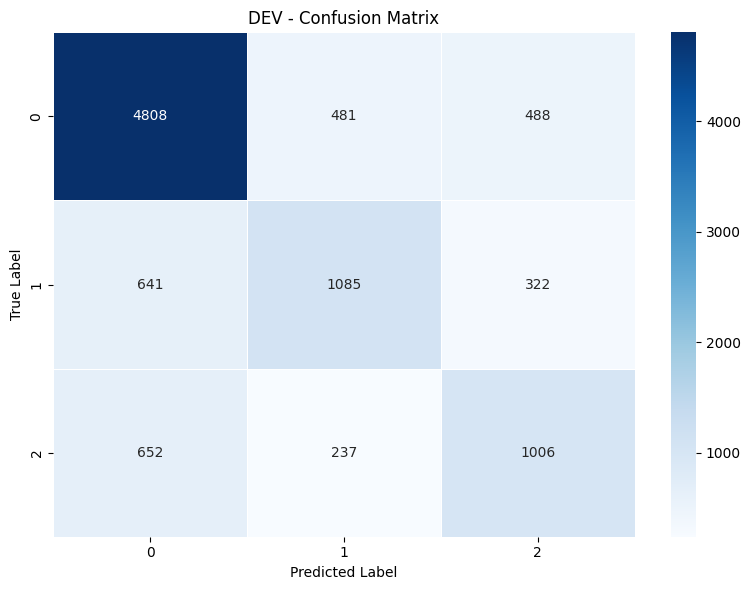

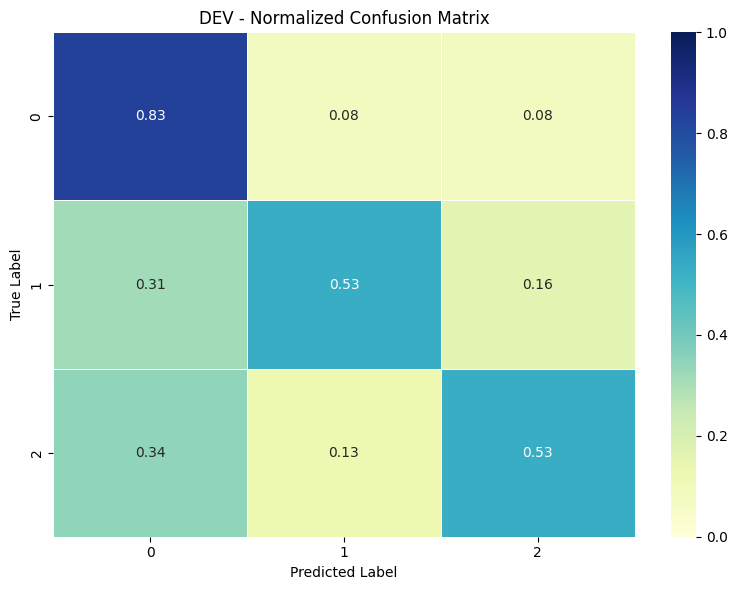


TEST EVALUATION
Accuracy                 : 0.7162
Macro Precision          : 0.6468
Weighted Precision       : 0.7099
Macro Recall             : 0.6304
Weighted Recall          : 0.7162
Macro F1                 : 0.6374
Weighted F1              : 0.7121
Balanced Accuracy        : 0.6304
Cohen's Kappa            : 0.4777
MCC                      : 0.4786
ROC-AUC (Macro)          : 0.8479
Log Loss                 : 0.7048

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

           0     0.8005    0.8410    0.8203      5882
           1     0.5996    0.5161    0.5548      1982
           2     0.5403    0.5339    0.5371      1856

    accuracy                         0.7162      9720
   macro avg     0.6468    0.6304    0.6374      9720
weighted avg     0.7099    0.7162    0.7121      9720



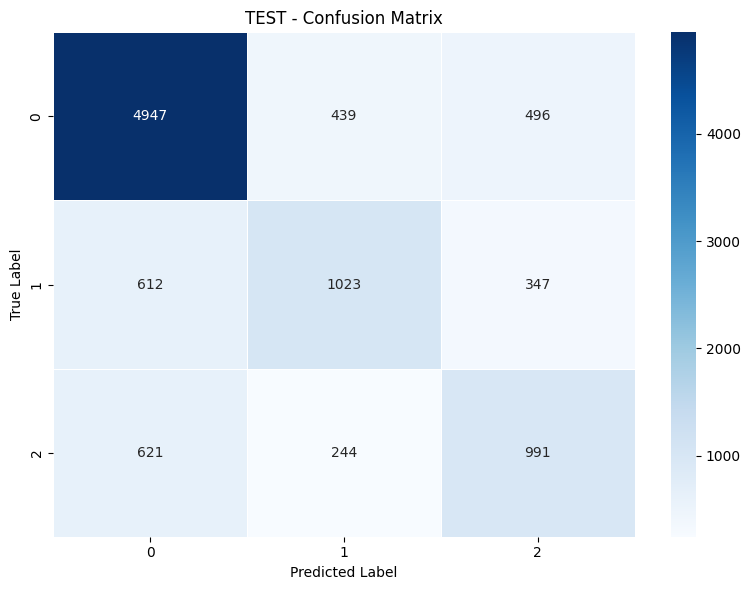

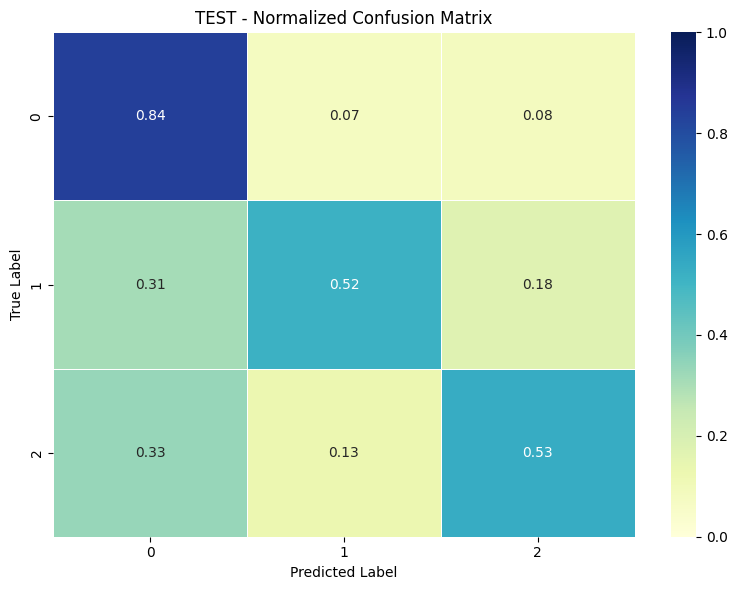


DEV vs TEST: COMPLETE METRIC COMPARISON


,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,Cohen's Kappa,MCC,ROC-AUC (Macro),Log Loss
Dataset,,,,,,,,,,,,
DEV,0.7098,0.6479,0.7032,0.6310,0.7098,0.6384,0.7056,0.6310,0.4737,0.4746,0.8415,0.7257
TEST,0.7162,0.6468,0.7099,0.6304,0.7162,0.6374,0.7121,0.6304,0.4777,0.4786,0.8479,0.7048


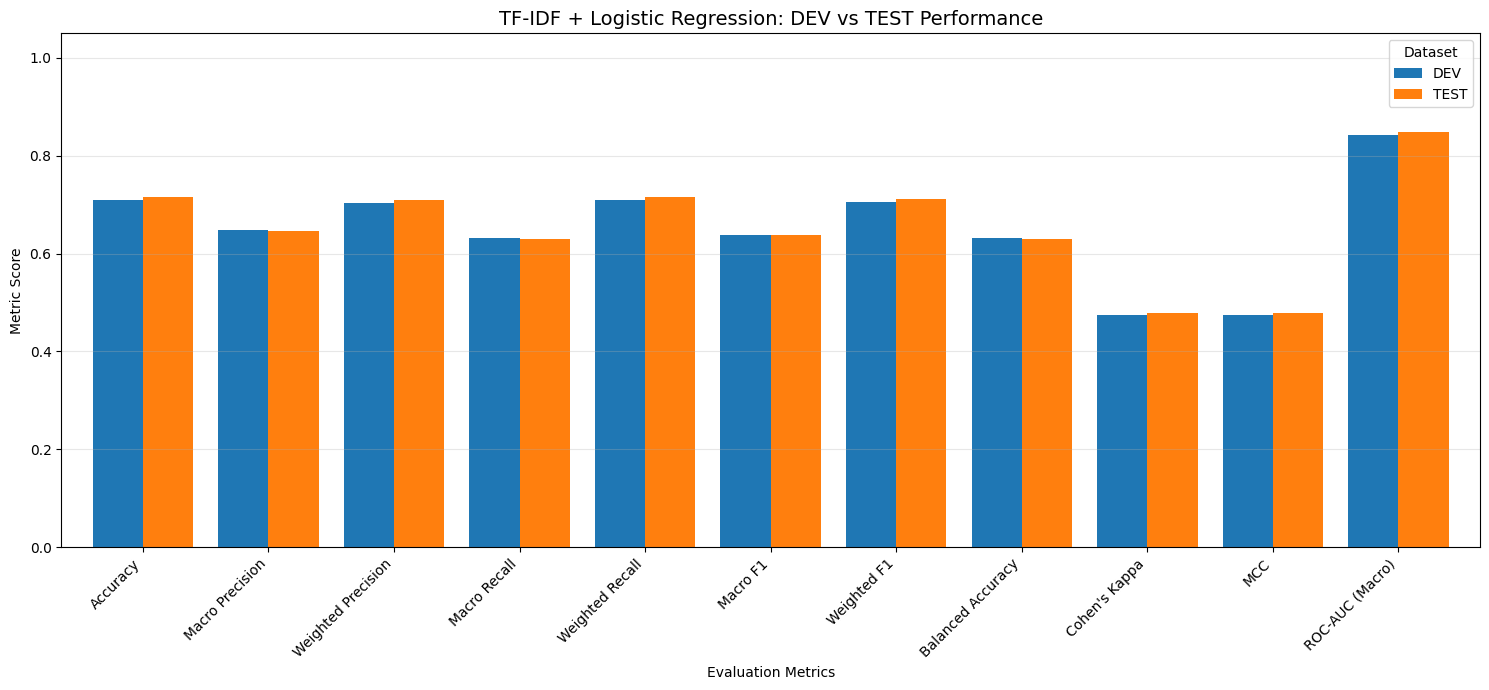

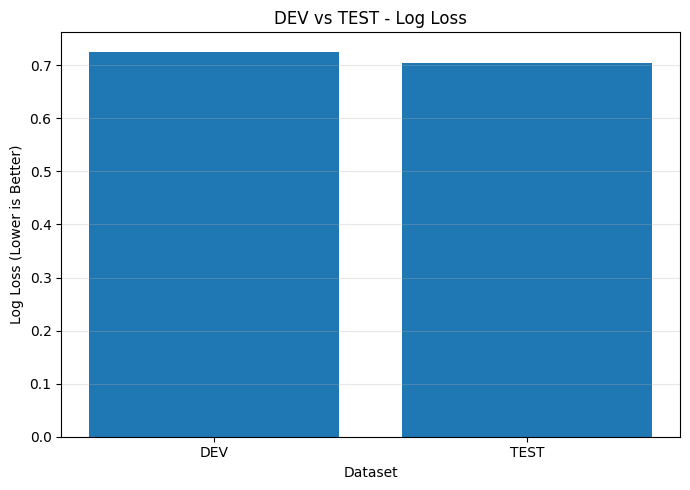

DEV Mean class-wise ROC-AUC: 0.8415
TEST Mean class-wise ROC-AUC: 0.8479


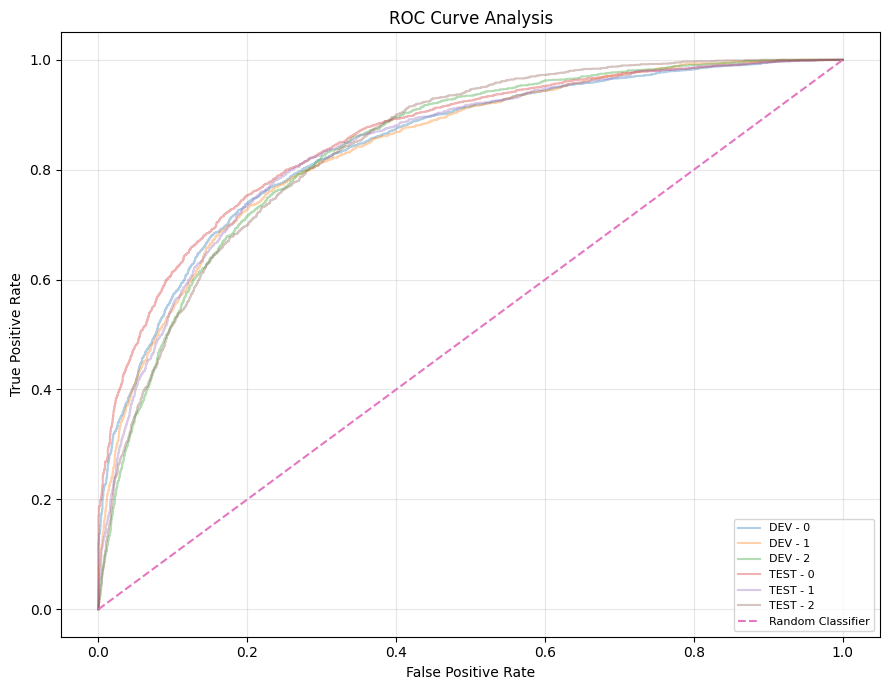


Evaluation completed successfully.
Results saved: tfidf_lr_evaluation_comparison.csv


In [10]:

# ============================================================
# CELL 8: TF-IDF + LOGISTIC REGRESSION
# COMPREHENSIVE MULTICLASS EVALUATION
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import (
    FunctionTransformer,
    MaxAbsScaler,
    LabelEncoder,
    label_binarize
)
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss,
    balanced_accuracy_score
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. Feature extraction
# ------------------------------------------------------------

def col(name):
    return FunctionTransformer(
        lambda df, c=name: df[c].fillna("").astype(str).tolist(),
        validate=False
    )

def word_vec(field):
    return Pipeline([
        ("get", col(field)),
        ("tfidf", TfidfVectorizer(
            analyzer="word",
            token_pattern=r"[A-Za-z\u0900-\u097F\u0B80-\u0BFF\u0C00-\u0C7F]+",
            lowercase=True,
            sublinear_tf=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            max_features=80000,
            stop_words=list(ALL_STOPWORDS)
        ))
    ])

def char_vec(field):
    return Pipeline([
        ("get", col(field)),
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            sublinear_tf=True,
            min_df=2,
            max_features=60000,
            lowercase=True
        ))
    ])

features = FeatureUnion([
    ("q_word", word_vec("question")),
    ("gt_word", word_vec("ground_truth")),
    ("r_word", word_vec("response")),
    ("r_char", char_vec("response")),
    ("raw", Pipeline([
        ("get", FunctionTransformer(
            lambda df: df[
                ["question", "ground_truth", "response"]
            ].fillna(""),
            validate=False
        )),
        ("ovl", OverlapFeatures()),
        ("sc", MaxAbsScaler())
    ]))
], n_jobs=1)

# ------------------------------------------------------------
# 2. Logistic Regression classifier
# ------------------------------------------------------------

lr = LogisticRegression(
    C=4.0,
    max_iter=3000,
    solver="liblinear",
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

model = Pipeline([
    ("feats", features),
    ("clf", lr)
])

# ------------------------------------------------------------
# 3. Train model
# ------------------------------------------------------------

print("=" * 65)
print("TRAINING TF-IDF + LOGISTIC REGRESSION")
print("=" * 65)

t0 = time.time()

model.fit(train_df, train_df["label"])

train_time = time.time() - t0

print(f"Training time: {train_time:.2f} seconds")
print(f"Training samples: {len(train_df)}")
print(f"Number of classes: {len(model.classes_)}")
print("Classes:", model.classes_)

# ------------------------------------------------------------
# 4. Comprehensive evaluation function
# ------------------------------------------------------------

def evaluate_model(name, df, fitted_model):

    y_true = df["label"].values
    y_pred = fitted_model.predict(df)

    # Predicted class probabilities
    y_prob = fitted_model.predict_proba(df)

    classes = fitted_model.classes_
    n_classes = len(classes)

    # --------------------------------------------------------
    # Core classification metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    macro_precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_precision = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_recall = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(y_true, y_pred)

    # --------------------------------------------------------
    # Agreement and correlation metrics
    # --------------------------------------------------------

    kappa = cohen_kappa_score(y_true, y_pred)

    mcc = matthews_corrcoef(y_true, y_pred)

    # --------------------------------------------------------
    # Probability-based metrics
    # --------------------------------------------------------

    ll = log_loss(
        y_true,
        y_prob,
        labels=classes
    )

    # Macro ROC-AUC: multiclass one-vs-rest
    try:
        if n_classes == 2:
            roc_auc = roc_auc_score(
                y_true,
                y_prob[:, 1]
            )
        else:
            roc_auc = roc_auc_score(
                y_true,
                y_prob,
                labels=classes,
                multi_class="ovr",
                average="macro"
            )
    except ValueError as e:
        print(f"ROC-AUC unavailable for {name}: {e}")
        roc_auc = np.nan

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    metrics = {
        "Dataset": name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Weighted Precision": weighted_precision,
        "Macro Recall": macro_recall,
        "Weighted Recall": weighted_recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Balanced Accuracy": balanced_acc,
        "Cohen's Kappa": kappa,
        "MCC": mcc,
        "ROC-AUC (Macro)": roc_auc,
        "Log Loss": ll
    }

    # --------------------------------------------------------
    # Print detailed results
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print(f"{name} EVALUATION")
    print("=" * 65)

    for metric, value in metrics.items():
        if metric != "Dataset":
            print(f"{metric:<25}: {value:.4f}")

    print("\nCLASSIFICATION REPORT")
    print("-" * 65)

    print(classification_report(
        y_true,
        y_pred,
        labels=classes,
        target_names=[str(c) for c in classes],
        digits=4,
        zero_division=0
    ))

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # Normalized confusion matrix
    # --------------------------------------------------------

    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        labels=classes,
        normalize="true"
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        vmin=0,
        vmax=1
    )

    plt.title(f"{name} - Normalized Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    return metrics, y_true, y_pred, y_prob


# ------------------------------------------------------------
# 5. Evaluate DEV and TEST
# ------------------------------------------------------------

dev_results, dev_y, dev_pred, dev_prob = evaluate_model(
    "DEV",
    dev_df,
    model
)

test_results, test_y, test_pred, test_prob = evaluate_model(
    "TEST",
    test_df,
    model
)

# ------------------------------------------------------------
# 6. Consolidated metric comparison
# ------------------------------------------------------------

comparison_df = pd.DataFrame([
    dev_results,
    test_results
])

comparison_df = comparison_df.set_index("Dataset")

print("\n" + "=" * 75)
print("DEV vs TEST: COMPLETE METRIC COMPARISON")
print("=" * 75)

display(comparison_df.round(4))

# ------------------------------------------------------------
# 7. Metric comparison visualization
# ------------------------------------------------------------

plot_metrics = [
    "Accuracy",
    "Macro Precision",
    "Weighted Precision",
    "Macro Recall",
    "Weighted Recall",
    "Macro F1",
    "Weighted F1",
    "Balanced Accuracy",
    "Cohen's Kappa",
    "MCC",
    "ROC-AUC (Macro)"
]

comparison_df[plot_metrics].T.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title(
    "TF-IDF + Logistic Regression: DEV vs TEST Performance",
    fontsize=14
)

plt.ylabel("Metric Score")
plt.xlabel("Evaluation Metrics")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Log loss comparison
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(
    comparison_df.index,
    comparison_df["Log Loss"]
)

plt.title("DEV vs TEST - Log Loss")
plt.ylabel("Log Loss (Lower is Better)")
plt.xlabel("Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. ROC curves (Binary and Multiclass)
# ------------------------------------------------------------

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = model.classes_
n_classes = len(classes)

datasets = {
    "DEV": (dev_y, dev_prob),
    "TEST": (test_y, test_prob)
}

plt.figure(figsize=(9, 7))

for dataset_name, (y_true, y_prob) in datasets.items():

    y_bin = label_binarize(
        y_true,
        classes=classes
    )

    if n_classes == 2:

        fpr, tpr, _ = roc_curve(
            y_true,
            y_prob[:, 1],
            pos_label=classes[1]
        )

        roc_value = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{dataset_name} (AUC={roc_value:.4f})"
        )

    else:

        class_aucs = []

        for i, cls in enumerate(classes):

            # Skip classes with no positive or negative samples
            if len(np.unique(y_bin[:, i])) < 2:
                continue

            fpr, tpr, _ = roc_curve(
                y_bin[:, i],
                y_prob[:, i]
            )

            roc_value = auc(fpr, tpr)

            class_aucs.append(roc_value)

        if class_aucs:
            print(
                f"{dataset_name} Mean class-wise ROC-AUC: "
                f"{np.mean(class_aucs):.4f}"
            )

            # Display class-wise curves
            for i, cls in enumerate(classes):

                if len(np.unique(y_bin[:, i])) < 2:
                    continue

                fpr, tpr, _ = roc_curve(
                    y_bin[:, i],
                    y_prob[:, i]
                )

                plt.plot(
                    fpr,
                    tpr,
                    alpha=0.35,
                    label=f"{dataset_name} - {cls}"
                )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Analysis")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. Save evaluation results
# ------------------------------------------------------------

comparison_df.to_csv(
    "tfidf_lr_evaluation_comparison.csv"
)

print("\nEvaluation completed successfully.")
print("Results saved: tfidf_lr_evaluation_comparison.csv")

In [11]:
# ============================================================
# CELL 8 (FIXED): picklable column extractors — NO lambdas
# ============================================================
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
import time

# -------- top-level picklable transformers --------
class ColumnSelector:
    """Pick a single column from a DataFrame and return it as a list of str."""
    def __init__(self, column: str):
        self.column = column
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.column].astype(str).tolist()

class MultiColumnSelector:
    """Return a DataFrame with the given columns (used for OverlapFeatures)."""
    def __init__(self, columns):
        self.columns = list(columns)
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.columns].copy()

class SeriesToList:
    """If a transformer returns a DataFrame of one column, flatten to list."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        # ColumnSelector already returns a list; MultiColumnSelector returns a DF.
        if hasattr(X, "columns") and len(X.columns) == 1:
            return X.iloc[:, 0].astype(str).tolist()
        return X

# -------- vectorizer builders (all pickle-safe) --------
def make_word_vec(field: str) -> Pipeline:
    return Pipeline([
        ("get", ColumnSelector(field)),
        ("tfidf", TfidfVectorizer(
            analyzer="word",
            token_pattern=r"[A-Za-z\u0900-\u097F\u0B80-\u0BFF\u0C00-\u0C7F]+",
            lowercase=True, sublinear_tf=True,
            ngram_range=(1, 2), min_df=2, max_df=0.95,
            max_features=80_000,
            stop_words=list(ALL_STOPWORDS),
        )),
    ])

def make_char_vec(field: str) -> Pipeline:
    return Pipeline([
        ("get", ColumnSelector(field)),
        ("tfidf", TfidfVectorizer(
            analyzer="char_wb", ngram_range=(3, 5),
            sublinear_tf=True, min_df=2, max_features=60_000,
            lowercase=True,
        )),
    ])

def make_overlap_pipe() -> Pipeline:
    return Pipeline([
        ("get", MultiColumnSelector(["question", "ground_truth", "response"])),
        ("ovl", OverlapFeatures()),          # top-level class from Cell 7
        ("sc",  MaxAbsScaler()),
    ])

# -------- assemble FeatureUnion --------
features = FeatureUnion([
    ("q_word", make_word_vec("question")),
    ("gt_word", make_word_vec("ground_truth")),
    ("r_word", make_word_vec("response")),
    ("r_char", make_char_vec("response")),
    ("raw",    make_overlap_pipe()),
], n_jobs=1)

# -------- model --------
lr = LogisticRegression(
    C=4.0, max_iter=3000, solver="liblinear",
    class_weight="balanced", n_jobs=-1,
)
model = Pipeline([("feats", features), ("clf", lr)])

# -------- train + evaluate (same as before) --------
t0 = time.time()
model.fit(train_df, train_df["label"])
print(f"Train time: {time.time()-t0:.1f}s")

def evaluate(name, df):
    y_pred = model.predict(df)
    acc = accuracy_score(df["label"], y_pred)
    f1m = f1_score(df["label"], y_pred, average="macro")
    print(f"\n=== {name}  acc={acc:.4f}  macro-F1={f1m:.4f} ===")
    print(classification_report(df["label"], y_pred, target_names=LABELS, digits=4))
    print("Confusion matrix:\n", confusion_matrix(df["label"], y_pred))
    return acc, f1m

evaluate("DEV",  dev_df)
evaluate("TEST", test_df)

Train time: 26.8s

=== DEV  acc=0.7098  macro-F1=0.6384 ===
                   precision    recall  f1-score   support

          Correct     0.7881    0.8323    0.8096      5777
        Incorrect     0.6018    0.5298    0.5635      2048
Partially Correct     0.5540    0.5309    0.5422      1895

         accuracy                         0.7098      9720
        macro avg     0.6479    0.6310    0.6384      9720
     weighted avg     0.7032    0.7098    0.7056      9720

Confusion matrix:
 [[4808  481  488]
 [ 641 1085  322]
 [ 652  237 1006]]

=== TEST  acc=0.7162  macro-F1=0.6374 ===
                   precision    recall  f1-score   support

          Correct     0.8005    0.8410    0.8203      5882
        Incorrect     0.5996    0.5161    0.5548      1982
Partially Correct     0.5403    0.5339    0.5371      1856

         accuracy                         0.7162      9720
        macro avg     0.6468    0.6304    0.6374      9720
     weighted avg     0.7099    0.7162    0.7121   

(0.7161522633744856, 0.6373871951060712)

In [12]:
# ============================================================
# CELL 9 (FIXED): tuner + ensemble — same logic, pickle-safe builders
# ============================================================
from sklearn.metrics import f1_score

def build(C=4.0, use_svc=False):
    clf = (CalibratedClassifierCV(
                LinearSVC(C=0.5, class_weight="balanced", dual="auto"),
                cv=3, method="sigmoid")
           if use_svc else
           LogisticRegression(C=C, max_iter=3000, solver="liblinear",
                              class_weight="balanced"))
    return Pipeline([("feats", features), ("clf", clf)])

best = (None, -1.0, None)
for C in [0.5, 1.0, 2.0, 4.0, 8.0]:
    m = build(C=C)
    m.fit(train_df, train_df["label"])
    f1m = f1_score(dev_df["label"], m.predict(dev_df), average="macro")
    print(f"C={C:<4} dev macro-F1={f1m:.4f}")
    if f1m > best[1]:
        best = (C, f1m, m)

C_best, dev_best, _ = best
print(f"\nBest C={C_best} (dev macro-F1={dev_best:.4f})")

import pandas as pd
train_dev = pd.concat([train_df, dev_df], ignore_index=True)

lr_final  = build(C=C_best).fit(train_dev, train_dev["label"])
svc_final = build(use_svc=True).fit(train_dev, train_dev["label"])

ens = VotingClassifier(
    estimators=[("lr", lr_final), ("svc", svc_final)],
    voting="soft", n_jobs=-1,
).fit(train_dev, train_dev["label"])

for name, m in [("LR", lr_final), ("SVC", svc_final), ("ENSEMBLE", ens)]:
    yp = m.predict(test_df)
    print(f"\n{name:9s} test acc={accuracy_score(test_df['label'], yp):.4f} "
          f"macro-F1={f1_score(test_df['label'], yp, average='macro'):.4f}")
    print(classification_report(test_df["label"], yp, target_names=LABELS, digits=4))

C=0.5  dev macro-F1=0.6430
C=1.0  dev macro-F1=0.6424
C=2.0  dev macro-F1=0.6400
C=4.0  dev macro-F1=0.6384
C=8.0  dev macro-F1=0.6364

Best C=0.5 (dev macro-F1=0.6430)

LR        test acc=0.7229 macro-F1=0.6553
                   precision    recall  f1-score   support

          Correct     0.8216    0.8211    0.8214      5882
        Incorrect     0.5977    0.5525    0.5742      1982
Partially Correct     0.5485    0.5938    0.5702      1856

         accuracy                         0.7229      9720
        macro avg     0.6559    0.6558    0.6553      9720
     weighted avg     0.7238    0.7229    0.7230      9720


SVC       test acc=0.7303 macro-F1=0.6339
                   precision    recall  f1-score   support

          Correct     0.7727    0.9031    0.8328      5882
        Incorrect     0.6489    0.4717    0.5463      1982
Partially Correct     0.6068    0.4591    0.5227      1856

         accuracy                         0.7303      9720
        macro avg     0.6761    

In [13]:
# ============================================================
# CELL 10 (FIXED): save artifacts — now pickles cleanly
# ============================================================
import joblib, json

joblib.dump(ens, "tfidf_lr_hallucination.joblib", compress=3)
with open("label_classes.json", "w") as f:
    json.dump(LABELS, f)
print("Saved model + labels")

# ---- Sanity check: reload and re-predict ----
ens_loaded = joblib.load("tfidf_lr_hallucination.joblib")
assert (ens_loaded.predict(test_df) == ens.predict(test_df)).all()
print("Reload check: OK")

test_pred = ens.predict(test_df)
test_df = test_df.copy()
test_df["pred_label"] = test_pred
test_df["pred_name"]  = [LABELS[i] for i in test_pred]

for grp in ["language", "model_name"]:
    print(f"\n=== Accuracy by {grp} ===")
    print(test_df.groupby(grp).apply(
        lambda d: (d["label"] == d["pred_label"]).mean()
    ).round(4))

print("\n=== Error analysis (top 5 misclassified) ===")
bad = test_df[test_df["label"] != test_df["pred_label"]]
for _, r in bad.head(5).iterrows():
    print(f"\n[{LABELS[r['label']]} -> {r['pred_name']}] ({r['language']})")
    print("Q :", r["question"][:120])
    print("GT:", r["ground_truth"][:120])
    print("R :", r["response"][:120])

Saved model + labels
Reload check: OK

=== Accuracy by language ===
language
EN       0.7286
HI       0.7669
HI-EN    0.7426
NE       0.7134
TA       0.7210
TE       0.7169
dtype: float64

=== Accuracy by model_name ===
model_name
Claude Sonnet 5.5      0.7395
DeepSeek-V4.1-Flash    0.7383
GLM-5.3 Flash          0.7537
GPT-5.6 Luna           0.7315
Gemini 3               0.7160
Qwen 3.7               0.7105
dtype: float64

=== Error analysis (top 5 misclassified) ===

[Correct -> Partially Correct] (EN)
Q : How much did the International Campaign to Save the Monuments of Nubia cost?
GT: The campaign to save the monuments of Nubia cost US$80 million.
R : About US$80 million

[Correct -> Partially Correct] (EN)
Q : What is the process by which a country gets a site considered for World Heritage listing, from the Tentative List to the
GT: A country first identifies its significant cultural and natural sites in a Tentative List.It can then place sites from t
R : A state first places the si